In [65]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import glob

print("Libraries successfully imported!")


Libraries successfully imported!


In [66]:

import os

repo_url = "https://github.com/himawannugraha23/ICBP_MYOR-Financial-Analysis.git"
repo_folder = "ICBP_MYOR-Financial-Analysis"

if not os.path.exists(repo_folder):
    !git clone {repo_url}

print("GitHub repository connected!")


GitHub repository connected!


In [67]:

for root, dirs, files in os.walk(repo_folder):
    level = root.replace(repo_folder, "").count(os.sep)
    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")


ICBP_MYOR-Financial-Analysis/
    README.md
    visualizations/
        07_profitability_benchmarking.png
        financial_ratio_comparison.png
        README.md
        financial_relationship_analysis.png
    python/
        README.md
    data/
        raw_financials_clean.csv
        data_quality_checks.csv
        README.md
    .git/
        description
        config
        index
        packed-refs
        HEAD
        info/
            exclude
        branches/
        logs/
            HEAD
            refs/
                remotes/
                    origin/
                        HEAD
                heads/
                    main
        objects/
            info/
            pack/
                pack-1ca9293f427767489d406db2f856281a5a354faf.rev
                pack-1ca9293f427767489d406db2f856281a5a354faf.pack
                pack-1ca9293f427767489d406db2f856281a5a354faf.idx
        hooks/
            fsmonitor-watchman.sample
            push-to-checkout.sample
      

In [68]:

from pathlib import Path

repo_path = Path("ICBP_MYOR-Financial-Analysis")

csv_files = sorted(repo_path.rglob("*.csv"))

print("CSV FILES FOUND:")
for file in csv_files:
    print(file)

print("\nTotal CSV files:", len(csv_files))


CSV FILES FOUND:
ICBP_MYOR-Financial-Analysis/data/data_quality_checks.csv
ICBP_MYOR-Financial-Analysis/data/raw_financials_clean.csv
ICBP_MYOR-Financial-Analysis/results/01_revenue_results.csv
ICBP_MYOR-Financial-Analysis/results/02_profitability_results.csv
ICBP_MYOR-Financial-Analysis/results/03_liquidity_results.csv
ICBP_MYOR-Financial-Analysis/results/04_solvency_results.csv
ICBP_MYOR-Financial-Analysis/results/05_cashflow_results.csv
ICBP_MYOR-Financial-Analysis/results/06_benchmarking_results.csv
ICBP_MYOR-Financial-Analysis/results/07_financial_trend_results.csv
ICBP_MYOR-Financial-Analysis/results/08_revenue_cagr_results.csv
ICBP_MYOR-Financial-Analysis/results/09_financial_ratio_results.csv
ICBP_MYOR-Financial-Analysis/results/10_ratio_comparison.csv
ICBP_MYOR-Financial-Analysis/results/11_relationship_analysis.csv
ICBP_MYOR-Financial-Analysis/results/12_correlation_results.csv
ICBP_MYOR-Financial-Analysis/results/13_earnings_quality.csv
ICBP_MYOR-Financial-Analysis/results/1

In [69]:

import pandas as pd
import numpy as np

# Load main financial dataset
file_path = "ICBP_MYOR-Financial-Analysis/data/raw_financials_clean.csv"

df = pd.read_csv(file_path)

print("Dataset successfully loaded!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head(10))


Dataset successfully loaded!
Number of rows: 12
Number of columns: 24


,company,fiscal_year,net_sales,cogs,gross_profit,selling_expense,ga_expense,operating_profit,interest_expense,profit_before_tax,...,trade_receivables,inventories,current_assets,total_assets,current_liabilities,total_liabilities,equity_parent,total_equity,cfo,capex_ppe
0,ICBP,2020,46641048.00,29416673.00,1.722438e+07,5549481.000,2557502.000,9.201012e+06,670545.000,9.958647e+06,...,5273416.000,4586940.000,20716223.00,1.035883e+08,9.176164e+06,5.327027e+07,29430291.00,50318053.00,9.336780e+06,1919170.000
1,ICBP,2021,56803733.00,36526493.00,2.027724e+07,6266392.000,2476091.000,1.165871e+07,1837077.000,9.935232e+06,...,6400930.000,5857217.000,33997637.00,1.180666e+08,1.889613e+07,6.334276e+07,33881903.00,54723863.00,7.989039e+06,2249751.000
2,ICBP,2022,64797516.00,43005230.00,2.179229e+07,6992683.000,2385558.000,1.337765e+07,2148657.000,7.525385e+06,...,6875504.000,7132321.000,31070365.00,1.153055e+08,1.003394e+07,5.783253e+07,36518511.00,57473007.00,8.804494e+06,1788876.000
3,ICBP,2023,67909901.00,42783641.00,2.512626e+07,7532318.000,2819429.000,1.438761e+07,2024713.000,1.144469e+07,...,7198158.000,6329482.000,36773465.00,1.192671e+08,1.046422e+07,5.716304e+07,40750169.00,62104033.00,1.241500e+07,1823830.000
4,ICBP,2024,72597188.00,45704099.00,2.689309e+07,7800327.000,2901602.000,1.632119e+07,2142348.000,1.149934e+07,...,8411723.000,7059605.000,44667549.00,1.260409e+08,1.092477e+07,5.899702e+07,45217376.00,67043885.00,1.245498e+07,2162129.000
5,ICBP,2025,74850923.00,48490503.00,2.636042e+07,7896903.000,2797680.000,1.665553e+07,2153025.000,1.372131e+07,...,9868682.000,7998980.000,51153716.00,1.355444e+08,1.231600e+07,6.186135e+07,51519743.00,73683004.00,1.210443e+07,3634570.000
6,MYOR,2020,24476953.74,17177830.78,7.299123e+06,3769234.916,698959.850,2.830928e+06,353822.336,2.683890e+06,...,5463984.744,2805111.592,12838729.16,1.977750e+07,3.559336e+06,8.506032e+06,11011069.91,11271468.05,3.715832e+06,634118.813
7,MYOR,2021,27904558.32,20981574.81,6.922984e+06,4539447.007,611220.587,1.772316e+06,320535.215,1.549649e+06,...,5911803.789,3034214.212,12969783.88,1.991765e+07,5.570773e+06,8.557622e+06,11118707.15,11360031.40,1.041955e+06,658964.760
8,MYOR,2022,30669405.97,23829982.63,6.839423e+06,3708573.358,697735.339,2.433115e+06,389182.678,2.506058e+06,...,6489405.390,3870496.137,14772623.98,2.227616e+07,5.636627e+06,9.441467e+06,12628400.60,12834694.09,1.619571e+06,804918.816
9,MYOR,2023,31485008.19,23077230.43,8.407778e+06,3357800.596,750501.815,4.299475e+06,302577.139,4.093716e+06,...,6098433.115,3556864.427,14738922.39,2.387040e+07,4.013201e+06,8.588316e+06,15039487.61,15282089.19,5.259182e+06,1653568.063


In [70]:

# Check dataset structure

print("DATASET INFORMATION")
print("===================")

df.info()

print("\nCOLUMN NAMES")
print(df.columns.tolist())

print("\nMISSING VALUES")
display(df.isnull().sum())

print("\nDUPLICATE ROWS")
print(df.duplicated().sum())


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 24 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   company              12 non-null     object 
 1   fiscal_year          12 non-null     int64  
 2   net_sales            12 non-null     float64
 3   cogs                 12 non-null     float64
 4   gross_profit         12 non-null     float64
 5   selling_expense      12 non-null     float64
 6   ga_expense           12 non-null     float64
 7   operating_profit     12 non-null     float64
 8   interest_expense     12 non-null     float64
 9   profit_before_tax    12 non-null     float64
 10  tax_expense          12 non-null     float64
 11  profit_for_year      12 non-null     float64
 12  net_income_parent    12 non-null     float64
 13  cash_equivalents     12 non-null     float64
 14  trade_receivables    12 non-null     float64
 15  inventories          1

,0
company,0
fiscal_year,0
net_sales,0
cogs,0
gross_profit,0
selling_expense,0
ga_expense,0
operating_profit,0
interest_expense,0
profit_before_tax,0



DUPLICATE ROWS
0


In [71]:

# Descriptive statistics

display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
fiscal_year,12.0,2.022500e+03,1.783765e+00,2.020000e+03,2.021000e+03,2.022500e+03,2.024000e+03,2025.0
net_sales,12.0,4.774090e+07,1.868992e+07,2.447695e+07,3.128111e+07,4.266131e+07,6.557561e+07,74850923.0
cogs,12.0,3.241277e+07,1.057825e+07,1.717783e+07,2.364179e+07,2.980299e+07,4.283904e+07,48490503.0
gross_profit,12.0,1.532813e+07,8.380117e+06,6.839423e+06,8.051505e+06,1.285832e+07,2.262578e+07,26893089.0
selling_expense,12.0,5.402092e+06,1.811227e+06,3.357801e+06,3.754070e+06,5.044464e+06,7.127592e+06,7896903.0
ga_expense,12.0,1.703318e+06,1.007935e+06,6.112206e+05,7.376163e+05,1.635594e+06,2.617546e+06,2901602.0
operating_profit,12.0,8.381384e+06,5.816298e+06,1.772316e+06,3.500516e+06,6.750244e+06,1.363014e+07,16655530.0
interest_expense,12.0,1.113398e+06,8.471068e+05,3.025771e+05,3.803426e+05,6.318210e+05,2.054122e+06,2153025.0
profit_before_tax,12.0,6.867959e+06,4.272152e+06,1.549649e+06,3.383347e+06,5.809550e+06,1.033016e+07,13721309.0
tax_expense,12.0,1.569839e+06,1.034970e+06,3.385959e+05,6.763335e+05,1.326017e+06,2.576545e+06,2979570.0


In [72]:

# Create a working copy

df_clean = df.copy()

print("Original dataset:", df.shape)
print("Working dataset:", df_clean.shape)

print("Working copy successfully created!")


Original dataset: (12, 24)
Working dataset: (12, 24)
Working copy successfully created!


In [73]:

# Missing value analysis

missing_report = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

display(missing_report)

# Duplicate analysis

print("Total duplicate rows:", df_clean.duplicated().sum())

# Check company-year uniqueness

if {"company", "fiscal_year"}.issubset(df_clean.columns):
    print(
        "Duplicate company-year records:",
        df_clean.duplicated(
            subset=["company", "fiscal_year"]
        ).sum()
    )


,Missing_Count,Missing_Percentage
company,0,0.0
fiscal_year,0,0.0
net_sales,0,0.0
cogs,0,0.0
gross_profit,0,0.0
selling_expense,0,0.0
ga_expense,0,0.0
operating_profit,0,0.0
interest_expense,0,0.0
profit_before_tax,0,0.0


Total duplicate rows: 0
Duplicate company-year records: 0


In [74]:

# Data type inspection

dtype_report = pd.DataFrame({
    "Column": df_clean.columns,
    "Data_Type": df_clean.dtypes.astype(str).values,
    "Unique_Values": [
        df_clean[col].nunique(dropna=True)
        for col in df_clean.columns
    ]
})

display(dtype_report)


,Column,Data_Type,Unique_Values
0,company,object,2
1,fiscal_year,int64,6
2,net_sales,float64,12
3,cogs,float64,12
4,gross_profit,float64,12
5,selling_expense,float64,12
6,ga_expense,float64,12
7,operating_profit,float64,12
8,interest_expense,float64,12
9,profit_before_tax,float64,12


In [75]:

# Financial reconciliation checks

required_columns = [
    "net_sales",
    "cogs",
    "gross_profit",
    "total_assets",
    "total_liabilities",
    "total_equity"
]

missing_columns = [
    col for col in required_columns
    if col not in df_clean.columns
]

if missing_columns:
    print("Columns not found:", missing_columns)

else:
    df_clean["gross_profit_check"] = (
        df_clean["net_sales"]
        - df_clean["cogs"]
        - df_clean["gross_profit"]
    )

    df_clean["balance_sheet_check"] = (
        df_clean["total_assets"]
        - df_clean["total_liabilities"]
        - df_clean["total_equity"]
    )

    display(
        df_clean[
            [
                "company",
                "fiscal_year",
                "gross_profit_check",
                "balance_sheet_check"
            ]
        ]
    )


,company,fiscal_year,gross_profit_check,balance_sheet_check
0,ICBP,2020,0.000000e+00,0.000
1,ICBP,2021,0.000000e+00,0.000
2,ICBP,2022,0.000000e+00,0.000
3,ICBP,2023,0.000000e+00,0.000
4,ICBP,2024,0.000000e+00,0.000
5,ICBP,2025,0.000000e+00,0.000
6,MYOR,2020,-2.793968e-09,0.005
7,MYOR,2021,2.000001e-03,0.001
8,MYOR,2022,1.000000e-03,0.005
9,MYOR,2023,1.000002e-03,-0.006


In [76]:

# Data quality summary

quality_summary = pd.DataFrame({
    "Metric": [
        "Total Rows",
        "Total Columns",
        "Missing Values",
        "Duplicate Rows",
        "Companies",
        "Reporting Years"
    ],
    "Value": [
        len(df_clean),
        len(df_clean.columns),
        int(df_clean.isnull().sum().sum()),
        int(df_clean.duplicated().sum()),
        df_clean["company"].nunique()
            if "company" in df_clean.columns else None,
        df_clean["fiscal_year"].nunique()
            if "fiscal_year" in df_clean.columns else None
    ]
})

display(quality_summary)


,Metric,Value
0,Total Rows,12
1,Total Columns,26
2,Missing Values,0
3,Duplicate Rows,0
4,Companies,2
5,Reporting Years,6


In [77]:

# MODULE 03: EXPLORATORY DATA ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Prepare dataset
eda = df_clean.copy()

# Ensure year is numeric
eda["fiscal_year"] = pd.to_numeric(
    eda["fiscal_year"], errors="coerce"
)

# Sort observations
eda = eda.sort_values(
    ["company", "fiscal_year"]
).reset_index(drop=True)

print("EDA dataset ready!")
display(eda.head())


EDA dataset ready!


,company,fiscal_year,net_sales,cogs,gross_profit,selling_expense,ga_expense,operating_profit,interest_expense,profit_before_tax,...,current_assets,total_assets,current_liabilities,total_liabilities,equity_parent,total_equity,cfo,capex_ppe,gross_profit_check,balance_sheet_check
0,ICBP,2020,46641048.0,29416673.0,17224375.0,5549481.0,2557502.0,9201012.0,670545.0,9958647.0,...,20716223.0,103588325.0,9176164.0,53270272.0,29430291.0,50318053.0,9336780.0,1919170.0,0.0,0.0
1,ICBP,2021,56803733.0,36526493.0,20277240.0,6266392.0,2476091.0,11658711.0,1837077.0,9935232.0,...,33997637.0,118066628.0,18896133.0,63342765.0,33881903.0,54723863.0,7989039.0,2249751.0,0.0,0.0
2,ICBP,2022,64797516.0,43005230.0,21792286.0,6992683.0,2385558.0,13377646.0,2148657.0,7525385.0,...,31070365.0,115305536.0,10033935.0,57832529.0,36518511.0,57473007.0,8804494.0,1788876.0,0.0,0.0
3,ICBP,2023,67909901.0,42783641.0,25126260.0,7532318.0,2819429.0,14387607.0,2024713.0,11444693.0,...,36773465.0,119267076.0,10464225.0,57163043.0,40750169.0,62104033.0,12415005.0,1823830.0,0.0,0.0
4,ICBP,2024,72597188.0,45704099.0,26893089.0,7800327.0,2901602.0,16321190.0,2142348.0,11499337.0,...,44667549.0,126040905.0,10924773.0,58997020.0,45217376.0,67043885.0,12454982.0,2162129.0,0.0,0.0


In [78]:

# Financial Overview

financial_overview = (
    eda.groupby("company")
    .agg(
        Total_Revenue=("net_sales", "sum"),
        Total_Gross_Profit=("gross_profit", "sum"),
        Total_Operating_Profit=("operating_profit", "sum"),
        Total_Net_Income=("profit_for_year", "sum"),
        Total_Assets_Average=("total_assets", "mean")
    )
    .round(2)
)

display(financial_overview)


,Total_Revenue,Total_Gross_Profit,Total_Operating_Profit,Total_Net_Income,Total_Assets_Average
company,,,,,
ICBP,3.836003e+08,1.376737e+08,81601696.00,49075659.00,1.196355e+08
MYOR,1.892904e+08,4.626387e+07,18974911.02,14501787.41,2.449175e+07


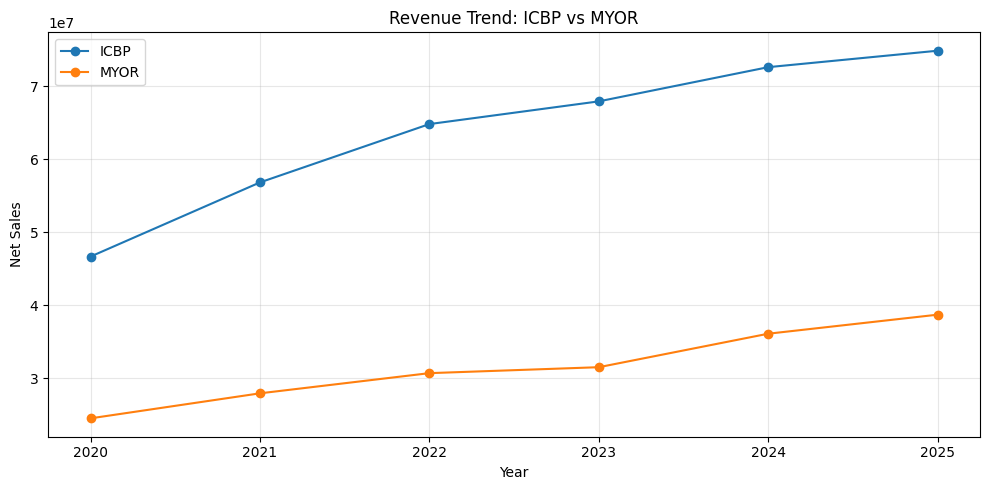

In [79]:

# Revenue Trend

plt.figure(figsize=(10, 5))

for company in eda["company"].unique():
    company_data = eda[eda["company"] == company]

    plt.plot(
        company_data["fiscal_year"],
        company_data["net_sales"],
        marker="o",
        label=company
    )

plt.title("Revenue Trend: ICBP vs MYOR")
plt.xlabel("Year")
plt.ylabel("Net Sales")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [80]:

# Calculate profitability ratios

eda["GPM"] = (
    eda["gross_profit"] / eda["net_sales"] * 100
)

eda["OPM"] = (
    eda["operating_profit"] / eda["net_sales"] * 100
)

eda["NPM"] = (
    eda["profit_for_year"] / eda["net_sales"] * 100
)

# Display profitability table

display(
    eda[
        [
            "company",
            "fiscal_year",
            "GPM",
            "OPM",
            "NPM"
        ]
    ].round(2)
)


,company,fiscal_year,GPM,OPM,NPM
0,ICBP,2020,36.93,19.73,15.91
1,ICBP,2021,35.70,20.52,13.91
2,ICBP,2022,33.63,20.65,8.83
3,ICBP,2023,37.00,21.19,12.47
4,ICBP,2024,37.04,22.48,12.14
5,ICBP,2025,35.22,22.25,14.37
6,MYOR,2020,29.82,11.57,8.57
7,MYOR,2021,24.81,6.35,4.34
8,MYOR,2022,22.30,7.93,6.42
9,MYOR,2023,26.70,13.66,10.31


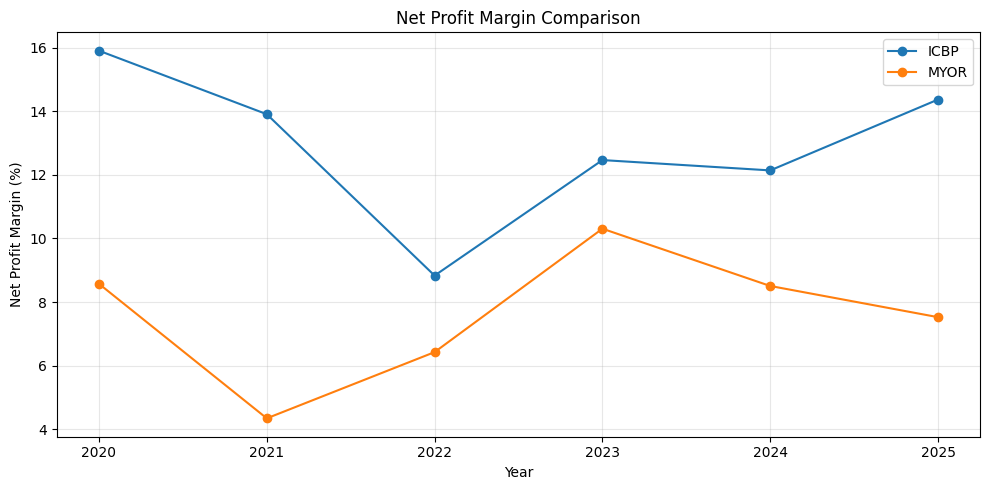

In [81]:

plt.figure(figsize=(10, 5))

for company in eda["company"].unique():
    company_data = eda[eda["company"] == company]

    plt.plot(
        company_data["fiscal_year"],
        company_data["NPM"],
        marker="o",
        label=company
    )

plt.title("Net Profit Margin Comparison")
plt.xlabel("Year")
plt.ylabel("Net Profit Margin (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [82]:

# Average financial performance

performance_comparison = (
    eda.groupby("company")
    .agg(
        Average_Revenue=("net_sales", "mean"),
        Average_GPM=("GPM", "mean"),
        Average_OPM=("OPM", "mean"),
        Average_NPM=("NPM", "mean"),
        Average_CFO=("cfo", "mean"),
        Average_Current_Assets=("current_assets", "mean"),
        Average_Total_Assets=("total_assets", "mean")
    )
    .round(2)
)

display(performance_comparison)


,Average_Revenue,Average_GPM,Average_OPM,Average_NPM,Average_CFO,Average_Current_Assets,Average_Total_Assets
company,,,,,,,
ICBP,63933384.83,35.92,21.14,12.94,10517454.50,36396492.50,1.196355e+08
MYOR,31548406.30,24.77,10.00,7.61,2447784.63,16030111.08,2.449175e+07


In [83]:

# Descriptive Statistics

financial_variables = [
    "net_sales",
    "gross_profit",
    "operating_profit",
    "profit_for_year",
    "total_assets",
    "total_liabilities",
    "total_equity",
    "cfo"
]

descriptive_stats = eda[
    financial_variables
].describe().T

display(descriptive_stats.round(2))


,count,mean,std,min,25%,50%,75%,max
net_sales,12.0,47740895.56,18689919.54,24476953.74,31281107.64,42661305.13,6.557561e+07,74850923.0
gross_profit,12.0,15328128.25,8380117.39,6839423.34,8051505.23,12858318.54,2.262578e+07,26893089.0
operating_profit,12.0,8381383.92,5816297.51,1772315.91,3500516.16,6750243.67,1.363014e+07,16655530.0
profit_for_year,12.0,5298120.53,3254895.62,1211052.65,2707013.59,4483533.05,8.041492e+06,10756109.0
total_assets,12.0,72063610.10,50320135.67,19777500.52,23471843.90,67484161.94,1.183667e+08,135544351.0
total_liabilities,12.0,34433647.97,25546672.44,8506032.46,9228178.90,33143640.65,5.812365e+07,63342765.0
total_equity,12.0,37629962.14,25050175.91,11271468.05,14670240.42,34340521.28,5.863076e+07,73683004.0
cfo,12.0,6482619.56,4648927.36,-463359.50,3040038.05,6624110.50,1.002869e+07,12454982.0


In [84]:

# MODULE 04.1: REVENUE GROWTH ANALYSIS

trend = eda.copy()

trend = trend.sort_values(
    ["company", "fiscal_year"]
)

trend["revenue_growth_pct"] = (
    trend.groupby("company")["net_sales"]
    .pct_change() * 100
)

display(
    trend[
        [
            "company",
            "fiscal_year",
            "net_sales",
            "revenue_growth_pct"
        ]
    ].round(2)
)


,company,fiscal_year,net_sales,revenue_growth_pct
0,ICBP,2020,46641048.00,NaN
1,ICBP,2021,56803733.00,21.79
2,ICBP,2022,64797516.00,14.07
3,ICBP,2023,67909901.00,4.80
4,ICBP,2024,72597188.00,6.90
5,ICBP,2025,74850923.00,3.10
6,MYOR,2020,24476953.74,NaN
7,MYOR,2021,27904558.32,14.00
8,MYOR,2022,30669405.97,9.91
9,MYOR,2023,31485008.19,2.66


In [85]:

# MODULE 04.2: REVENUE CAGR

revenue_cagr = []

for company, group in trend.groupby("company"):

    group = group.sort_values("fiscal_year")

    start_value = group["net_sales"].iloc[0]
    end_value = group["net_sales"].iloc[-1]

    start_year = group["fiscal_year"].iloc[0]
    end_year = group["fiscal_year"].iloc[-1]

    periods = end_year - start_year

    cagr = (
        (end_value / start_value) ** (1 / periods) - 1
    ) * 100 if start_value > 0 and periods > 0 else np.nan

    revenue_cagr.append({
        "company": company,
        "starting_revenue": start_value,
        "ending_revenue": end_value,
        "CAGR_pct": cagr
    })

cagr_df = pd.DataFrame(revenue_cagr)

display(cagr_df.round(2))


,company,starting_revenue,ending_revenue,CAGR_pct
0,ICBP,46641048.00,74850923.00,9.92
1,MYOR,24476953.74,38681562.26,9.58


,company,fiscal_year,revenue_index
0,ICBP,2020,100.00
1,ICBP,2021,121.79
2,ICBP,2022,138.93
3,ICBP,2023,145.60
4,ICBP,2024,155.65
5,ICBP,2025,160.48
6,MYOR,2020,100.00
7,MYOR,2021,114.00
8,MYOR,2022,125.30
9,MYOR,2023,128.63


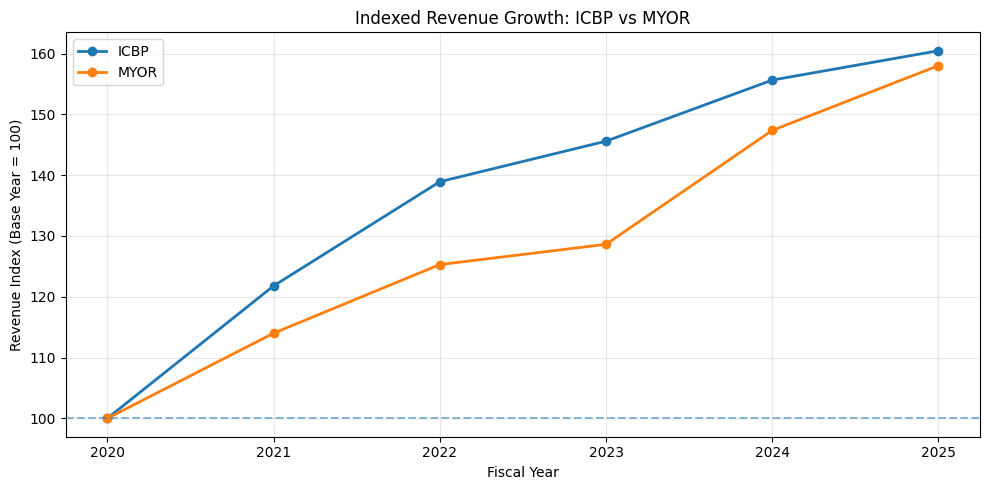

In [86]:

# MODULE 04.3: REVENUE INDEX

trend["revenue_index"] = (
    trend["net_sales"] /
    trend.groupby("company")["net_sales"].transform("first")
) * 100

display(
    trend[
        ["company", "fiscal_year", "revenue_index"]
    ].round(2)
)

# Visualization

plt.figure(figsize=(10, 5))

for company in trend["company"].unique():

    subset = trend[trend["company"] == company]

    plt.plot(
        subset["fiscal_year"],
        subset["revenue_index"],
        marker="o",
        linewidth=2,
        label=company
    )

plt.axhline(100, linestyle="--", alpha=0.5)

plt.title("Indexed Revenue Growth: ICBP vs MYOR")
plt.xlabel("Fiscal Year")
plt.ylabel("Revenue Index (Base Year = 100)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [87]:

# MODULE 04.4: NET INCOME GROWTH

trend["net_income_growth_pct"] = (
    trend.groupby("company")["profit_for_year"]
    .pct_change() * 100
)

display(
    trend[
        [
            "company",
            "fiscal_year",
            "profit_for_year",
            "net_income_growth_pct"
        ]
    ].round(2)
)


,company,fiscal_year,profit_for_year,net_income_growth_pct
0,ICBP,2020,7418574.00,NaN
1,ICBP,2021,7900282.00,6.49
2,ICBP,2022,5722194.00,-27.57
3,ICBP,2023,8465123.00,47.93
4,ICBP,2024,8813377.00,4.11
5,ICBP,2025,10756109.00,22.04
6,MYOR,2020,2098168.52,NaN
7,MYOR,2021,1211052.65,-42.28
8,MYOR,2022,1970064.54,62.67
9,MYOR,2023,3244872.09,64.71


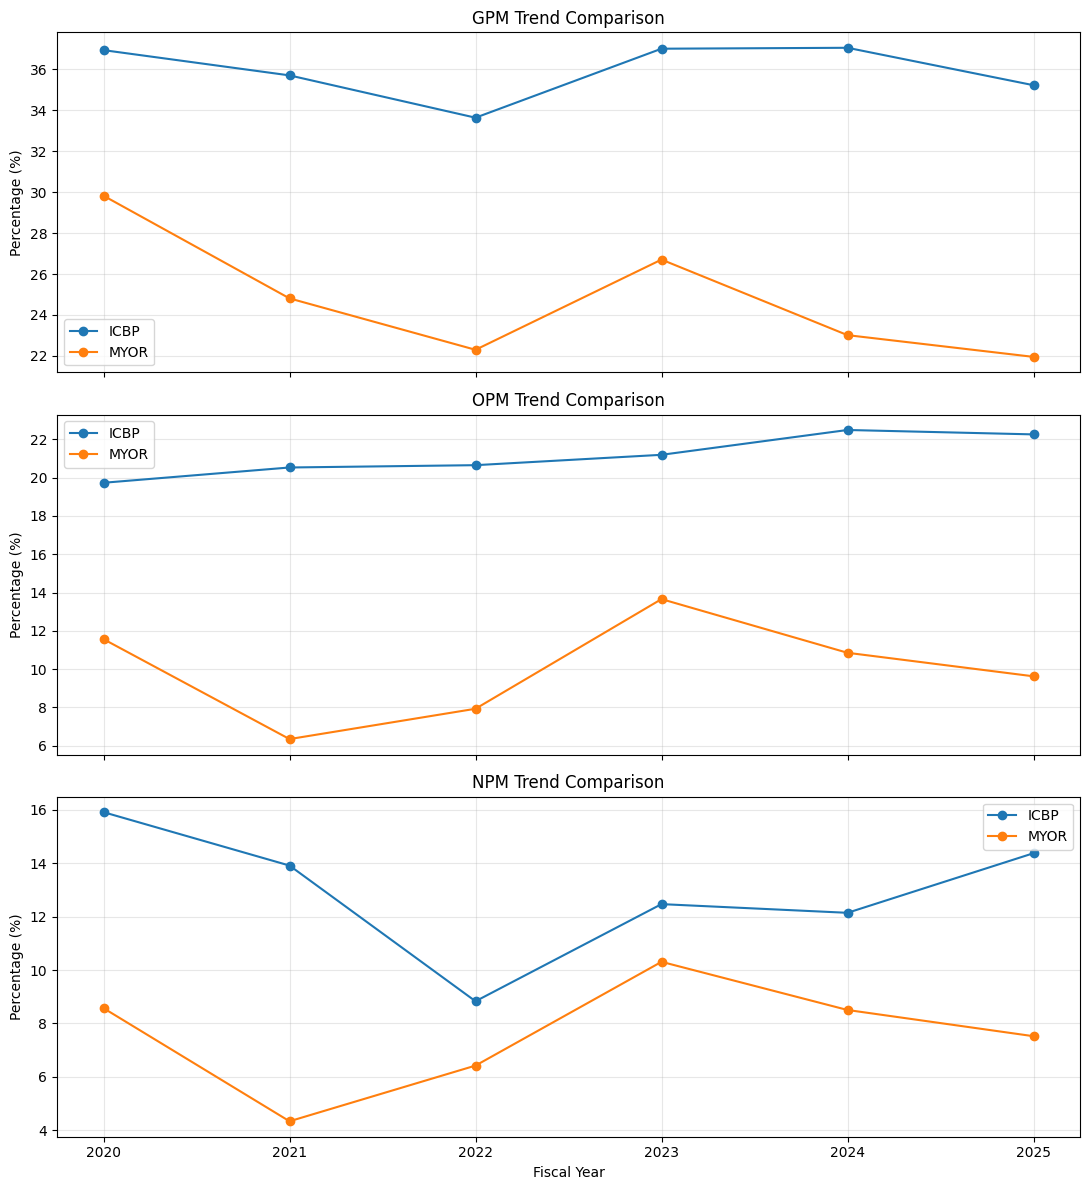

In [88]:

# MODULE 04.5: PROFITABILITY TREND

margin_columns = [
    "GPM",
    "OPM",
    "NPM"
]

fig, axes = plt.subplots(
    3, 1,
    figsize=(11, 12),
    sharex=True
)

for ax, metric in zip(axes, margin_columns):

    for company in trend["company"].unique():

        subset = trend[trend["company"] == company]

        ax.plot(
            subset["fiscal_year"],
            subset[metric],
            marker="o",
            label=company
        )

    ax.set_title(f"{metric} Trend Comparison")
    ax.set_ylabel("Percentage (%)")
    ax.grid(alpha=0.3)
    ax.legend()

axes[-1].set_xlabel("Fiscal Year")

plt.tight_layout()
plt.show()


In [89]:

# MODULE 04.6: TOTAL ASSET GROWTH

trend["asset_growth_pct"] = (
    trend.groupby("company")["total_assets"]
    .pct_change() * 100
)

asset_growth_summary = (
    trend.groupby("company")
    .agg(
        Initial_Assets=("total_assets", "first"),
        Final_Assets=("total_assets", "last"),
        Average_Assets=("total_assets", "mean"),
        Average_Asset_Growth=("asset_growth_pct", "mean")
    )
    .round(2)
)

display(asset_growth_summary)


,Initial_Assets,Final_Assets,Average_Assets,Average_Asset_Growth
company,,,,
ICBP,1.035883e+08,1.355444e+08,1.196355e+08,5.66
MYOR,1.977750e+07,3.138000e+07,2.449175e+07,9.96


In [90]:

from pathlib import Path

output_dir = Path(
    "ICBP_MYOR-Financial-Analysis/visualizations"
)

output_dir.mkdir(parents=True, exist_ok=True)

print("Visualization folder ready!")


Visualization folder ready!


In [91]:

# Export financial trend results

trend_results = trend[
    [
        "company",
        "fiscal_year",
        "net_sales",
        "revenue_growth_pct",
        "revenue_index",
        "profit_for_year",
        "net_income_growth_pct",
        "GPM",
        "OPM",
        "NPM",
        "total_assets",
        "asset_growth_pct"
    ]
]

trend_results.to_csv(
    "ICBP_MYOR-Financial-Analysis/results/07_financial_trend_results.csv",
    index=False
)

cagr_df.to_csv(
    "ICBP_MYOR-Financial-Analysis/results/08_revenue_cagr_results.csv",
    index=False
)

print("Financial trend results exported!")


Financial trend results exported!


In [92]:

# MODULE 05: FINANCIAL RATIO ANALYSIS

ratio_df = eda.copy()

ratio_df = ratio_df.sort_values(
    ["company", "fiscal_year"]
).reset_index(drop=True)

print("Financial ratio dataset prepared!")

display(ratio_df.head())


Financial ratio dataset prepared!


,company,fiscal_year,net_sales,cogs,gross_profit,selling_expense,ga_expense,operating_profit,interest_expense,profit_before_tax,...,total_liabilities,equity_parent,total_equity,cfo,capex_ppe,gross_profit_check,balance_sheet_check,GPM,OPM,NPM
0,ICBP,2020,46641048.0,29416673.0,17224375.0,5549481.0,2557502.0,9201012.0,670545.0,9958647.0,...,53270272.0,29430291.0,50318053.0,9336780.0,1919170.0,0.0,0.0,36.929648,19.727284,15.905676
1,ICBP,2021,56803733.0,36526493.0,20277240.0,6266392.0,2476091.0,11658711.0,1837077.0,9935232.0,...,63342765.0,33881903.0,54723863.0,7989039.0,2249751.0,0.0,0.0,35.697020,20.524551,13.908033
2,ICBP,2022,64797516.0,43005230.0,21792286.0,6992683.0,2385558.0,13377646.0,2148657.0,7525385.0,...,57832529.0,36518511.0,57473007.0,8804494.0,1788876.0,0.0,0.0,33.631360,20.645307,8.830885
3,ICBP,2023,67909901.0,42783641.0,25126260.0,7532318.0,2819429.0,14387607.0,2024713.0,11444693.0,...,57163043.0,40750169.0,62104033.0,12415005.0,1823830.0,0.0,0.0,36.999406,21.186317,12.465227
4,ICBP,2024,72597188.0,45704099.0,26893089.0,7800327.0,2901602.0,16321190.0,2142348.0,11499337.0,...,58997020.0,45217376.0,67043885.0,12454982.0,2162129.0,0.0,0.0,37.044257,22.481849,12.140108


In [93]:

# 5.1 LIQUIDITY RATIOS

ratio_df["current_ratio"] = (
    ratio_df["current_assets"] /
    ratio_df["current_liabilities"]
)

ratio_df["cash_ratio"] = (
    ratio_df["cash_equivalents"] /
    ratio_df["current_liabilities"]
)

liquidity_results = ratio_df[
    [
        "company",
        "fiscal_year",
        "current_ratio",
        "cash_ratio"
    ]
]

display(liquidity_results.round(2))


,company,fiscal_year,current_ratio,cash_ratio
0,ICBP,2020,2.26,1.04
1,ICBP,2021,1.80,1.08
2,ICBP,2022,3.10,1.57
3,ICBP,2023,3.51,1.85
4,ICBP,2024,4.09,2.32
5,ICBP,2025,4.15,2.37
6,MYOR,2020,3.61,1.06
7,MYOR,2021,2.33,0.54
8,MYOR,2022,2.62,0.58
9,MYOR,2023,3.67,1.04


In [94]:

# 5.2 SOLVENCY RATIOS

ratio_df["debt_to_equity"] = (
    ratio_df["total_liabilities"] /
    ratio_df["total_equity"]
)

ratio_df["debt_to_asset_pct"] = (
    ratio_df["total_liabilities"] /
    ratio_df["total_assets"] * 100
)

solvency_results = ratio_df[
    [
        "company",
        "fiscal_year",
        "debt_to_equity",
        "debt_to_asset_pct"
    ]
]

display(solvency_results.round(2))


,company,fiscal_year,debt_to_equity,debt_to_asset_pct
0,ICBP,2020,1.06,51.42
1,ICBP,2021,1.16,53.65
2,ICBP,2022,1.01,50.16
3,ICBP,2023,0.92,47.93
4,ICBP,2024,0.88,46.81
5,ICBP,2025,0.84,45.64
6,MYOR,2020,0.75,43.01
7,MYOR,2021,0.75,42.97
8,MYOR,2022,0.74,42.38
9,MYOR,2023,0.56,35.98


In [95]:

# 5.3 PROFITABILITY AND EFFICIENCY RATIOS

# Previous year balances
ratio_df["previous_year"] = (
    ratio_df.groupby("company")["fiscal_year"].shift(1)
)

ratio_df["previous_assets"] = (
    ratio_df.groupby("company")["total_assets"].shift(1)
)

ratio_df["previous_equity"] = (
    ratio_df.groupby("company")["equity_parent"].shift(1)
)

# Only use consecutive reporting years
valid_period = (
    ratio_df["fiscal_year"] -
    ratio_df["previous_year"] == 1
)

ratio_df["average_assets"] = np.where(
    valid_period,
    (
        ratio_df["total_assets"] +
        ratio_df["previous_assets"]
    ) / 2,
    np.nan
)

ratio_df["average_parent_equity"] = np.where(
    valid_period,
    (
        ratio_df["equity_parent"] +
        ratio_df["previous_equity"]
    ) / 2,
    np.nan
)

# ROA
ratio_df["ROA"] = (
    ratio_df["profit_for_year"] /
    ratio_df["average_assets"] * 100
)

# ROE
ratio_df["ROE"] = (
    ratio_df["net_income_parent"] /
    ratio_df["average_parent_equity"] * 100
)

# Asset Turnover
ratio_df["asset_turnover"] = (
    ratio_df["net_sales"] /
    ratio_df["average_assets"]
)

display(
    ratio_df[
        [
            "company",
            "fiscal_year",
            "average_assets",
            "average_parent_equity",
            "ROA",
            "ROE",
            "asset_turnover"
        ]
    ].round(2)
)


,company,fiscal_year,average_assets,average_parent_equity,ROA,ROE,asset_turnover
0,ICBP,2020,NaN,NaN,NaN,NaN,NaN
1,ICBP,2021,1.108275e+08,31656097.00,7.13,20.18,0.51
2,ICBP,2022,1.166861e+08,35200207.00,4.90,13.03,0.56
3,ICBP,2023,1.172863e+08,38634340.00,7.22,18.09,0.58
4,ICBP,2024,1.226540e+08,42983772.50,7.19,16.47,0.59
5,ICBP,2025,1.307926e+08,48368559.50,8.22,19.07,0.57
6,MYOR,2020,NaN,NaN,NaN,NaN,NaN
7,MYOR,2021,1.984758e+07,11064888.53,6.10,10.72,1.41
8,MYOR,2022,2.109691e+07,11873553.88,9.34,16.36,1.45
9,MYOR,2023,2.307328e+07,13833944.10,14.06,23.09,1.36


In [96]:

# 5.4 FINANCIAL RATIO COMPARISON

ratio_summary = (
    ratio_df.groupby("company")
    .agg(
        Average_Current_Ratio=("current_ratio", "mean"),
        Average_Cash_Ratio=("cash_ratio", "mean"),
        Average_DER=("debt_to_equity", "mean"),
        Average_DAR=("debt_to_asset_pct", "mean"),
        Average_ROA=("ROA", "mean"),
        Average_ROE=("ROE", "mean"),
        Average_Asset_Turnover=("asset_turnover", "mean")
    )
    .round(2)
)

display(ratio_summary)


,Average_Current_Ratio,Average_Cash_Ratio,Average_DER,Average_DAR,Average_ROA,Average_ROE,Average_Asset_Turnover
company,,,,,,,
ICBP,3.15,1.70,0.98,49.27,6.93,17.37,0.56
MYOR,3.04,0.79,0.71,41.38,10.09,17.08,1.37


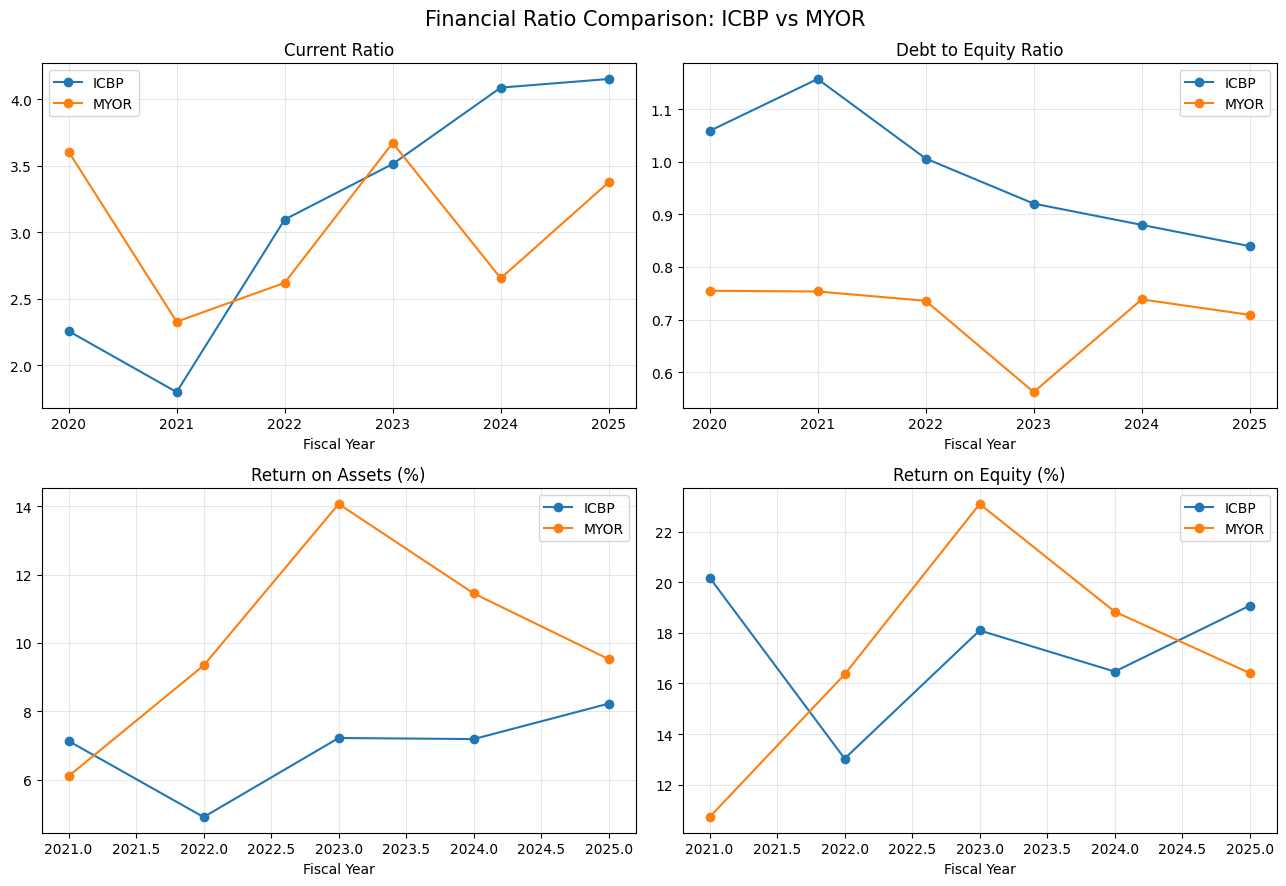

In [97]:

# 5.5 FINANCIAL RATIO VISUALIZATION

metrics = [
    ("current_ratio", "Current Ratio"),
    ("debt_to_equity", "Debt to Equity Ratio"),
    ("ROA", "Return on Assets (%)"),
    ("ROE", "Return on Equity (%)")
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, (metric, title) in zip(axes.flat, metrics):

    for company in ratio_df["company"].unique():

        subset = ratio_df[
            ratio_df["company"] == company
        ]

        ax.plot(
            subset["fiscal_year"],
            subset[metric],
            marker="o",
            label=company
        )

    ax.set_title(title)
    ax.set_xlabel("Fiscal Year")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Financial Ratio Comparison: ICBP vs MYOR",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [98]:

# 5.6 EXPORT RESULTS

from pathlib import Path

results_dir = Path(
    "ICBP_MYOR-Financial-Analysis/results"
)

visual_dir = Path(
    "ICBP_MYOR-Financial-Analysis/visualizations"
)

results_dir.mkdir(parents=True, exist_ok=True)
visual_dir.mkdir(parents=True, exist_ok=True)

# Export detailed ratios
ratio_df.to_csv(
    results_dir / "09_financial_ratio_results.csv",
    index=False
)

# Export company comparison
ratio_summary.to_csv(
    results_dir / "10_ratio_comparison.csv"
)

print("Financial ratio results successfully exported!")


Financial ratio results successfully exported!


In [99]:
plt.savefig(
    visual_dir / "financial_ratio_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [100]:

# MODULE 06: STATISTICAL & RELATIONSHIP ANALYSIS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

relationship_df = ratio_df.copy()

relationship_df = relationship_df.sort_values(
    ["company", "fiscal_year"]
).reset_index(drop=True)

print("Relationship analysis dataset prepared!")

display(relationship_df.head())


Relationship analysis dataset prepared!


,company,fiscal_year,net_sales,cogs,gross_profit,selling_expense,ga_expense,operating_profit,interest_expense,profit_before_tax,...,debt_to_equity,debt_to_asset_pct,previous_year,previous_assets,previous_equity,average_assets,average_parent_equity,ROA,ROE,asset_turnover
0,ICBP,2020,46641048.0,29416673.0,17224375.0,5549481.0,2557502.0,9201012.0,670545.0,9958647.0,...,1.058671,51.424977,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ICBP,2021,56803733.0,36526493.0,20277240.0,6266392.0,2476091.0,11658711.0,1837077.0,9935232.0,...,1.157498,53.650016,2020.0,103588325.0,29430291.0,110827476.5,31656097.0,7.128451,20.180874,0.512542
2,ICBP,2022,64797516.0,43005230.0,21792286.0,6992683.0,2385558.0,13377646.0,2148657.0,7525385.0,...,1.006255,50.155900,2021.0,118066628.0,33881903.0,116686082.0,35200207.0,4.903922,13.032216,0.555315
3,ICBP,2023,67909901.0,42783641.0,25126260.0,7532318.0,2819429.0,14387607.0,2024713.0,11444693.0,...,0.920440,47.928603,2022.0,115305536.0,36518511.0,117286306.0,38634340.0,7.217486,18.094193,0.579010
4,ICBP,2024,72597188.0,45704099.0,26893089.0,7800327.0,2901602.0,16321190.0,2142348.0,11499337.0,...,0.879976,46.807836,2023.0,119267076.0,40750169.0,122653990.5,42983772.5,7.185561,16.469864,0.591886


In [101]:

# 6.1 CREATE ADDITIONAL VARIABLES

relationship_df["revenue_growth_pct"] = (
    relationship_df.groupby("company")["net_sales"]
    .pct_change(fill_method=None) * 100
)

previous_income = (
    relationship_df.groupby("company")["profit_for_year"]
    .shift(1)
)

# Growth is meaningful here only when previous income is positive
relationship_df["net_income_growth_pct"] = np.where(
    previous_income > 0,
    (
        relationship_df["profit_for_year"] /
        previous_income - 1
    ) * 100,
    np.nan
)

relationship_df["CFO_margin_pct"] = (
    relationship_df["cfo"] /
    relationship_df["net_sales"] * 100
)

# Replace infinite values
relationship_df = relationship_df.replace(
    [np.inf, -np.inf], np.nan
)

display(
    relationship_df[
        [
            "company",
            "fiscal_year",
            "revenue_growth_pct",
            "net_income_growth_pct",
            "NPM",
            "ROA",
            "ROE",
            "asset_turnover",
            "debt_to_equity",
            "CFO_margin_pct"
        ]
    ].round(2)
)


,company,fiscal_year,revenue_growth_pct,net_income_growth_pct,NPM,ROA,ROE,asset_turnover,debt_to_equity,CFO_margin_pct
0,ICBP,2020,NaN,NaN,15.91,NaN,NaN,NaN,1.06,20.02
1,ICBP,2021,21.79,6.49,13.91,7.13,20.18,0.51,1.16,14.06
2,ICBP,2022,14.07,-27.57,8.83,4.90,13.03,0.56,1.01,13.59
3,ICBP,2023,4.80,47.93,12.47,7.22,18.09,0.58,0.92,18.28
4,ICBP,2024,6.90,4.11,12.14,7.19,16.47,0.59,0.88,17.16
5,ICBP,2025,3.10,22.04,14.37,8.22,19.07,0.57,0.84,16.17
6,MYOR,2020,NaN,NaN,8.57,NaN,NaN,NaN,0.75,15.18
7,MYOR,2021,14.00,-42.28,4.34,6.10,10.72,1.41,0.75,3.73
8,MYOR,2022,9.91,62.67,6.42,9.34,16.36,1.45,0.74,5.28
9,MYOR,2023,2.66,64.71,10.31,14.06,23.09,1.36,0.56,16.70


In [102]:

# 6.2 SPEARMAN CORRELATION

variables = [
    "revenue_growth_pct",
    "net_income_growth_pct",
    "NPM",
    "ROA",
    "ROE",
    "asset_turnover",
    "debt_to_equity",
    "CFO_margin_pct"
]

correlation_results = []

for company, group in relationship_df.groupby("company"):

    for var1, var2 in combinations(variables, 2):

        pair = group[[var1, var2]].dropna()

        if len(pair) >= 4:

            correlation = pair[var1].corr(
                pair[var2],
                method="spearman"
            )

            correlation_results.append({
                "company": company,
                "variable_1": var1,
                "variable_2": var2,
                "observations": len(pair),
                "spearman_correlation": correlation
            })

correlation_df = pd.DataFrame(correlation_results)

display(
    correlation_df.sort_values(
        ["company", "spearman_correlation"],
        ascending=[True, False]
    ).round(3)
)


,company,variable_1,variable_2,observations,spearman_correlation
5,ICBP,revenue_growth_pct,debt_to_equity,5,0.900
14,ICBP,NPM,ROE,5,0.900
8,ICBP,net_income_growth_pct,ROA,5,0.800
26,ICBP,asset_turnover,CFO_margin_pct,5,0.800
7,ICBP,net_income_growth_pct,NPM,5,0.700
12,ICBP,net_income_growth_pct,CFO_margin_pct,5,0.700
13,ICBP,NPM,ROA,5,0.700
21,ICBP,ROA,CFO_margin_pct,5,0.700
9,ICBP,net_income_growth_pct,ROE,5,0.600
17,ICBP,NPM,CFO_margin_pct,6,0.543


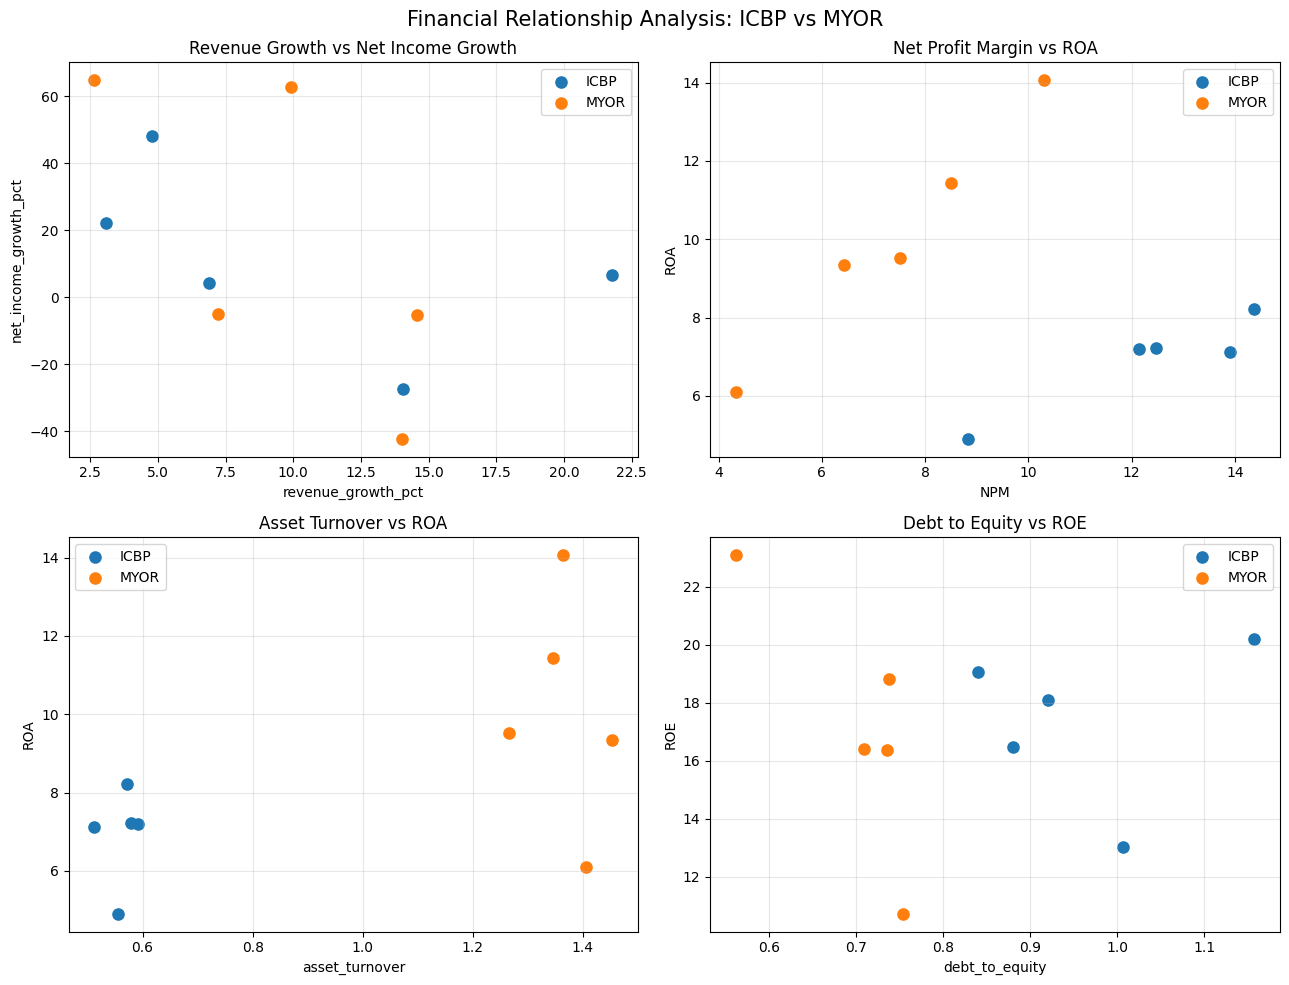

In [103]:

# 6.3 RELATIONSHIP VISUALIZATION

relationships = [
    (
        "revenue_growth_pct",
        "net_income_growth_pct",
        "Revenue Growth vs Net Income Growth"
    ),
    (
        "NPM",
        "ROA",
        "Net Profit Margin vs ROA"
    ),
    (
        "asset_turnover",
        "ROA",
        "Asset Turnover vs ROA"
    ),
    (
        "debt_to_equity",
        "ROE",
        "Debt to Equity vs ROE"
    )
]

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 10)
)

for ax, (x, y, title) in zip(
    axes.flat, relationships
):

    for company in relationship_df["company"].unique():

        subset = relationship_df[
            relationship_df["company"] == company
        ]

        ax.scatter(
            subset[x],
            subset[y],
            label=company,
            s=65
        )

    ax.set_title(title)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle(
    "Financial Relationship Analysis: ICBP vs MYOR",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [104]:

# 6.4 CASH FLOW AND EARNINGS QUALITY

relationship_df["CFO_to_Net_Income"] = np.where(
    relationship_df["profit_for_year"] > 0,
    relationship_df["cfo"] /
    relationship_df["profit_for_year"],
    np.nan
)

earnings_quality = relationship_df[
    [
        "company",
        "fiscal_year",
        "profit_for_year",
        "cfo",
        "CFO_margin_pct",
        "CFO_to_Net_Income"
    ]
].copy()

display(earnings_quality.round(3))


,company,fiscal_year,profit_for_year,cfo,CFO_margin_pct,CFO_to_Net_Income
0,ICBP,2020,7.418574e+06,9.336780e+06,20.018,1.259
1,ICBP,2021,7.900282e+06,7.989039e+06,14.064,1.011
2,ICBP,2022,5.722194e+06,8.804494e+06,13.588,1.539
3,ICBP,2023,8.465123e+06,1.241500e+07,18.282,1.467
4,ICBP,2024,8.813377e+06,1.245498e+07,17.156,1.413
5,ICBP,2025,1.075611e+07,1.210443e+07,16.171,1.125
6,MYOR,2020,2.098169e+06,3.715832e+06,15.181,1.771
7,MYOR,2021,1.211053e+06,1.041955e+06,3.734,0.860
8,MYOR,2022,1.970065e+06,1.619571e+06,5.281,0.822
9,MYOR,2023,3.244872e+06,5.259182e+06,16.704,1.621


In [105]:

# 6.5 BUSINESS RELATIONSHIP SUMMARY

relationship_summary = (
    relationship_df.groupby("company")
    .agg(
        Average_Revenue_Growth=(
            "revenue_growth_pct", "mean"
        ),
        Average_Net_Income_Growth=(
            "net_income_growth_pct", "mean"
        ),
        Average_NPM=("NPM", "mean"),
        Average_ROA=("ROA", "mean"),
        Average_ROE=("ROE", "mean"),
        Average_Asset_Turnover=(
            "asset_turnover", "mean"
        ),
        Average_CFO_Margin=(
            "CFO_margin_pct", "mean"
        ),
        Average_CFO_Conversion=(
            "CFO_to_Net_Income", "mean"
        )
    )
    .round(2)
)

display(relationship_summary)


,Average_Revenue_Growth,Average_Net_Income_Growth,Average_NPM,Average_ROA,Average_ROE,Average_Asset_Turnover,Average_CFO_Margin,Average_CFO_Conversion
company,,,,,,,,
ICBP,10.13,10.6,12.94,6.93,17.37,0.56,16.55,1.30
MYOR,9.67,14.9,7.61,10.09,17.08,1.37,8.12,1.02


In [106]:

# 6.6 EXPORT ANALYSIS RESULTS

from pathlib import Path

results_dir = Path(
    "ICBP_MYOR-Financial-Analysis/results"
)

visual_dir = Path(
    "ICBP_MYOR-Financial-Analysis/visualizations"
)

results_dir.mkdir(parents=True, exist_ok=True)
visual_dir.mkdir(parents=True, exist_ok=True)

# Export detailed relationship data
relationship_df.to_csv(
    results_dir / "11_relationship_analysis.csv",
    index=False
)

# Export correlation results
correlation_df.to_csv(
    results_dir / "12_correlation_results.csv",
    index=False
)

# Export earnings quality
earnings_quality.to_csv(
    results_dir / "13_earnings_quality.csv",
    index=False
)

# Export business summary
relationship_summary.to_csv(
    results_dir / "14_relationship_summary.csv"
)

print("All Module 06 results exported successfully!")


All Module 06 results exported successfully!


In [107]:
plt.savefig(
    visual_dir / "financial_relationship_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

In [108]:

# MODULE 07: BUSINESS INSIGHTS

business_df = relationship_df.copy()

# Company-level financial performance
business_summary = (
    business_df.groupby("company")
    .agg(
        Total_Revenue=("net_sales", "sum"),
        Average_Revenue=("net_sales", "mean"),
        Total_Gross_Profit=("gross_profit", "sum"),
        Total_Operating_Profit=("operating_profit", "sum"),
        Total_Net_Income=("profit_for_year", "sum"),
        Average_GPM=("GPM", "mean"),
        Average_OPM=("OPM", "mean"),
        Average_NPM=("NPM", "mean"),
        Average_ROA=("ROA", "mean"),
        Average_ROE=("ROE", "mean"),
        Average_Current_Ratio=("current_ratio", "mean"),
        Average_DER=("debt_to_equity", "mean"),
        Total_CFO=("cfo", "sum")
    )
    .round(2)
)

display(business_summary)


,Total_Revenue,Average_Revenue,Total_Gross_Profit,Total_Operating_Profit,Total_Net_Income,Average_GPM,Average_OPM,Average_NPM,Average_ROA,Average_ROE,Average_Current_Ratio,Average_DER,Total_CFO
company,,,,,,,,,,,,,
ICBP,3.836003e+08,63933384.83,1.376737e+08,81601696.00,49075659.00,35.92,21.14,12.94,6.93,17.37,3.15,0.98,63104727.00
MYOR,1.892904e+08,31548406.30,4.626387e+07,18974911.02,14501787.41,24.77,10.00,7.61,10.09,17.08,3.04,0.71,14686707.77


In [109]:

# 7.1 BUSINESS GROWTH ASSESSMENT

growth_assessment = cagr_df[
    ["company", "starting_revenue", "ending_revenue", "CAGR_pct"]
].copy()

growth_assessment = growth_assessment.rename(
    columns={
        "starting_revenue": "Initial_Revenue",
        "ending_revenue": "Final_Revenue",
        "CAGR_pct": "Revenue_CAGR_pct"
    }
)

display(growth_assessment.round(2))


,company,Initial_Revenue,Final_Revenue,Revenue_CAGR_pct
0,ICBP,46641048.00,74850923.00,9.92
1,MYOR,24476953.74,38681562.26,9.58


In [110]:

# 7.2 PROFITABILITY ASSESSMENT

profitability_assessment = (
    business_df.groupby("company")
    .agg(
        Gross_Profit_Margin=("GPM", "mean"),
        Operating_Profit_Margin=("OPM", "mean"),
        Net_Profit_Margin=("NPM", "mean"),
        Return_on_Assets=("ROA", "mean"),
        Return_on_Equity=("ROE", "mean")
    )
    .round(2)
)

display(profitability_assessment)


,Gross_Profit_Margin,Operating_Profit_Margin,Net_Profit_Margin,Return_on_Assets,Return_on_Equity
company,,,,,
ICBP,35.92,21.14,12.94,6.93,17.37
MYOR,24.77,10.00,7.61,10.09,17.08


In [111]:

# 7.3 FINANCIAL RISK ASSESSMENT

risk_assessment = (
    business_df.groupby("company")
    .agg(
        Average_Current_Ratio=("current_ratio", "mean"),
        Minimum_Current_Ratio=("current_ratio", "min"),
        Average_DER=("debt_to_equity", "mean"),
        Maximum_DER=("debt_to_equity", "max"),
        Average_CFO_Conversion=("CFO_to_Net_Income", "mean"),
        Negative_CFO_Years=(
            "cfo",
            lambda x: (x < 0).sum()
        )
    )
    .round(2)
)

display(risk_assessment)


,Average_Current_Ratio,Minimum_Current_Ratio,Average_DER,Maximum_DER,Average_CFO_Conversion,Negative_CFO_Years
company,,,,,,
ICBP,3.15,1.80,0.98,1.16,1.30,0
MYOR,3.04,2.33,0.71,0.75,1.02,1


In [112]:

# 7.4 COMPARATIVE PERFORMANCE SCORECARD

# Collect financial performance metrics
metrics = {
    "Revenue CAGR (%)": cagr_df.set_index("company")["CAGR_pct"],

    "Average GPM (%)": business_summary["Average_GPM"],

    "Average OPM (%)": business_summary["Average_OPM"],

    "Average NPM (%)": business_summary["Average_NPM"],

    "Average ROA (%)": business_summary["Average_ROA"],

    "Average ROE (%)": business_summary["Average_ROE"],

    "Average Current Ratio": business_summary["Average_Current_Ratio"],

    "Average DER": business_summary["Average_DER"]
}

# Create comparison table
scorecard = pd.DataFrame(metrics).T

# Arrange company columns
scorecard = scorecard.reindex(columns=["ICBP", "MYOR"])

# Display results
display(scorecard.round(2))


company,ICBP,MYOR
Revenue CAGR (%),9.92,9.58
Average GPM (%),35.92,24.77
Average OPM (%),21.14,10.00
Average NPM (%),12.94,7.61
Average ROA (%),6.93,10.09
Average ROE (%),17.37,17.08
Average Current Ratio,3.15,3.04
Average DER,0.98,0.71


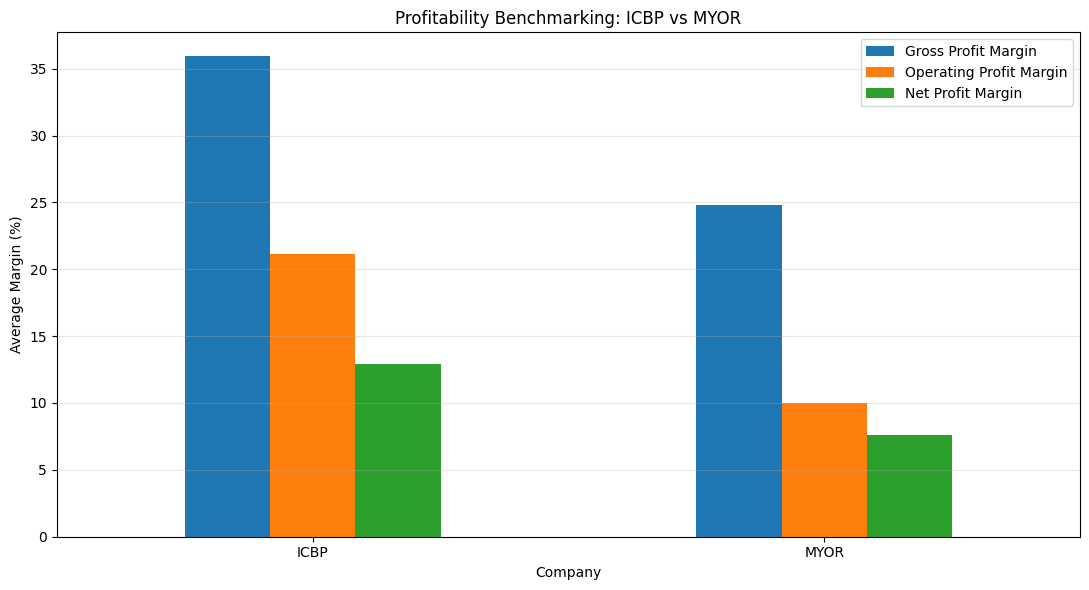

In [113]:

# 7.5 STRATEGIC PERFORMANCE VISUALIZATION

plot_metrics = [
    "Average_GPM",
    "Average_OPM",
    "Average_NPM"
]

plot_data = business_summary[plot_metrics]

plot_data.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Profitability Benchmarking: ICBP vs MYOR")
plt.xlabel("Company")
plt.ylabel("Average Margin (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.legend([
    "Gross Profit Margin",
    "Operating Profit Margin",
    "Net Profit Margin"
])

plt.tight_layout()

plt.savefig(
    "ICBP_MYOR-Financial-Analysis/visualizations/07_profitability_benchmarking.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [114]:

# 7.6 EVIDENCE-BASED BUSINESS INSIGHTS

insights = []

def add_insight(category, metric, company_a, company_b, value_a, value_b, interpretation):
    insights.append({
        "Category": category,
        "Metric": metric,
        "Company_A": company_a,
        "Company_B": company_b,
        "Value_A": value_a,
        "Value_B": value_b,
        "Finding": interpretation
    })

companies = business_summary.index.tolist()

if len(companies) == 2:
    a, b = companies

    comparisons = [
        ("Growth", "Revenue CAGR", cagr_df.set_index("company")["CAGR_pct"]),
        ("Profitability", "Average NPM", business_summary["Average_NPM"]),
        ("Efficiency", "Average ROA", business_summary["Average_ROA"]),
        ("Liquidity", "Current Ratio", business_summary["Average_Current_Ratio"])
    ]

    for category, metric, values in comparisons:
        va = values.get(a, np.nan)
        vb = values.get(b, np.nan)

        if pd.notna(va) and pd.notna(vb):
            if va > vb:
                finding = f"{a} records a higher {metric} than {b}."
            elif vb > va:
                finding = f"{b} records a higher {metric} than {a}."
            else:
                finding = f"Both companies record the same {metric}."

            add_insight(
                category, metric, a, b, va, vb, finding
            )

insights_df = pd.DataFrame(insights)

display(insights_df)


,Category,Metric,Company_A,Company_B,Value_A,Value_B,Finding
0,Growth,Revenue CAGR,ICBP,MYOR,9.922291,9.58455,ICBP records a higher Revenue CAGR than MYOR.
1,Profitability,Average NPM,ICBP,MYOR,12.940000,7.61000,ICBP records a higher Average NPM than MYOR.
2,Efficiency,Average ROA,ICBP,MYOR,6.930000,10.09000,MYOR records a higher Average ROA than ICBP.
3,Liquidity,Current Ratio,ICBP,MYOR,3.150000,3.04000,ICBP records a higher Current Ratio than MYOR.


In [115]:

# 7.7 EXPORT BUSINESS INSIGHTS

from pathlib import Path

results_dir = Path(
    "ICBP_MYOR-Financial-Analysis/results"
)

results_dir.mkdir(parents=True, exist_ok=True)

business_summary.to_csv(
    results_dir / "15_business_summary.csv"
)

growth_assessment.to_csv(
    results_dir / "16_growth_assessment.csv",
    index=False
)

profitability_assessment.to_csv(
    results_dir / "17_profitability_assessment.csv"
)

risk_assessment.to_csv(
    results_dir / "18_risk_assessment.csv"
)

scorecard.to_csv(
    results_dir / "19_performance_scorecard.csv"
)

insights_df.to_csv(
    results_dir / "20_business_insights.csv",
    index=False
)

print("Module 07 results exported successfully!")


Module 07 results exported successfully!


In [116]:

from pathlib import Path

repo = Path("ICBP_MYOR-Financial-Analysis")

print("PYTHON PROJECT OUTPUTS")
print("======================")

for folder in ["results", "visualizations"]:
    path = repo / folder

    print(f"\n{folder.upper()}")

    if path.exists():
        for file in sorted(path.iterdir()):
            print("-", file.name)
    else:
        print("Folder not found")


PYTHON PROJECT OUTPUTS

RESULTS
- 01_revenue_results.csv
- 02_profitability_results.csv
- 03_liquidity_results.csv
- 04_solvency_results.csv
- 05_cashflow_results.csv
- 06_benchmarking_results.csv
- 07_financial_trend_results.csv
- 08_revenue_cagr_results.csv
- 09_financial_ratio_results.csv
- 10_ratio_comparison.csv
- 11_relationship_analysis.csv
- 12_correlation_results.csv
- 13_earnings_quality.csv
- 14_relationship_summary.csv
- 15_business_summary.csv
- 16_growth_assessment.csv
- 17_profitability_assessment.csv
- 18_risk_assessment.csv
- 19_performance_scorecard.csv
- 20_business_insights.csv
- README.md

VISUALIZATIONS
- 07_profitability_benchmarking.png
- README.md
- financial_ratio_comparison.png
- financial_relationship_analysis.png
